# Feature engineering: technical features and "smooshing" correlated factors

Goal: build an **extended train/test CSV** that adds
1. **technical features** (moving averages of each stock's own past returns), and
2. **composite features** that squeeze several of the 20 factors into one.

## Ideas for turning several features into one

| # | Idea | Uses labels? | Why / risk |
|---|---|---|---|
| A | **Cluster average**: group factors that are highly correlated, average each group (sign-aligned) | No | Cheap, stable, removes redundancy. The factors are already cross-sectional percentile ranks (0.01-1), so a plain average is meaningful. |
| B | **PCA, first component per group** | No | Same grouping, but weights come from the data instead of being equal. |
| C | **IC-weighted blend**: weight each factor by its historical rank-correlation with the future return | **Yes (train only)** | Keeps the factors that actually predict. Higher overfit risk, so weights are fit on train and frozen for test. |
| D | **Cluster, then keep the best**: greedy pick by IC, skip anything correlated with an already picked factor | **Yes (train only)** | Your "keep the most correlated to future returns" idea, but without picking five copies of the same signal. |
| E | **Hand-built differences/ratios** from economic reasoning (e.g. 3M turnover minus 12M turnover = turnover trend) | No | Interpretable; captures *change*, which an average hides. |

**Leakage rules used throughout**
- Anything fit from data (cluster membership, PCA loadings, IC weights, signs) is fit on **train only** and applied unchanged to test.
- The label on snapshot *t* is earned in month *t+1*. Technical features at snapshot *t* only use returns **already realized by the end of month t**, i.e. labels of snapshots *t-1* and earlier.
- The test period was already viewed in this project, so test numbers below are a sanity check, not a clean out-of-sample claim.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)   # pandas stack() notice
pd.set_option("display.width", 160, "display.max_columns", 50)

# Locate the project folder whether the notebook is run from here or its parent.
HERE = Path.cwd()
ROOT = HERE if (HERE / "mlfactor_long_only_train.csv").exists() else HERE.parent
OUT = ROOT / "0_7_Feature_Engineering"

FEATURES = ["Ocf_Toa","Tot_Debt_Rev","Net_Debt","Total_Liabilities_Total_Assets","Share_Turn_3M",
            "Fcf_Tbv","Debtequity","Ocf_Ce","Fcf_Yld","Ocf_Tbv","Div_Yld","Netdebtyield",
            "Share_Turn_12M","Tev_Less_Mktcap","Bb_Yld","Ev_Ebitda","Total_Debt_Capital",
            "Share_Turn_6M","Capex_Sales","Ocf_Ta"]
TARGET = "R1M_Usd"

train = pd.read_csv(ROOT / "mlfactor_long_only_train.csv", parse_dates=["date"]).sort_values(["date","stock_id"]).reset_index(drop=True)
test  = pd.read_csv(ROOT / "mlfactor_long_only_test.csv",  parse_dates=["date"]).sort_values(["date","stock_id"]).reset_index(drop=True)
train["split"], test["split"] = "train", "test"

# Log forward return: tames the +2700% outlier and is additive across months.
for d in (train, test):
    d["fwd_log_ret"] = np.log1p(d[TARGET])

print("train", train.shape, train.date.min().date(), "->", train.date.max().date())
print("test ", test.shape,  test.date.min().date(),  "->", test.date.max().date())

train (140739, 25) 1999-12-31 -> 2009-11-30
test  (127740, 25) 2009-12-31 -> 2018-11-30


## 1. Technical features: moving averages for every asset

The data has **no prices**, only monthly returns (the label). So "moving average of each asset" is built from each stock's own **past realized returns**:

- `ta_ret_1m` - last month's return (short-term reversal signal)
- `ta_ma_3m / 6m / 12m` - simple moving average of monthly returns
- `ta_ma_cross` - 3M average minus 12M average (is the short trend above the long trend?)
- `ta_px_vs_ma_3m / 6m / 12m` - a synthetic price rebuilt from compounded returns, divided by its own simple moving average of **price** (the classic "price above its moving average" signal)
- `ta_mom_12_1` - 12-month momentum skipping the most recent month
- `ta_vol_6m / 12m` - rolling standard deviation of log returns

Timing: the return realized **during** month *t* is the label stored on snapshot *t-1*. So at snapshot *t* we shift the label by one month. Windows must be fully populated, so a gap in a stock's history gives `NaN` instead of silently bridging the gap.

Train and test are stacked **only to build history** (test row Dec-2009 may use returns from late 2009 that sit in train). That is allowed: those returns are in the past at that snapshot.

In [2]:
def build_technical(panel):
    """Return one row per (date, stock_id) of moving-average style features built from PAST returns only."""
    # Wide table: rows = snapshot month, columns = stock. Label on row t is earned in month t+1.
    wide = panel.pivot(index="date", columns="stock_id", values=TARGET)
    months = pd.date_range(wide.index.min(), wide.index.max(), freq="ME")
    assert wide.index.equals(months), "months must be consecutive so shifts mean 'one month'"

    # r.loc[t] = return realized DURING month t (known at the month-t snapshot) = label of snapshot t-1.
    r = wide.shift(1)
    lr = np.log1p(r)                      # log returns, additive over time

    feats = {}
    feats["ta_ret_1m"] = r
    for k in (3, 6, 12):
        # simple moving average of monthly returns; NaN unless all k months exist
        feats[f"ta_ma_{k}m"] = r.rolling(k, min_periods=k).mean()
    feats["ta_ma_cross"] = feats["ta_ma_3m"] - feats["ta_ma_12m"]

    # price / SMA(price) - 1 using a price rebuilt from returns.
    # price_{t-j} / price_t = exp(-(lr_t + lr_{t-1} + ... + lr_{t-j+1}))
    for k in (3, 6, 12):
        back = lr * 0.0                   # cumulative log return from t-j to t (0 at j=0)
        acc = lr * 0.0
        for j in range(k):
            acc = acc + np.exp(-back)     # price_{t-j}/price_t
            back = back + lr.shift(j)
        feats[f"ta_px_vs_ma_{k}m"] = 1.0 / (acc / k) - 1.0

    # 12-1 momentum: compounded return over months t-11..t-1, skipping month t
    feats["ta_mom_12_1"] = np.expm1(lr.shift(1).rolling(11, min_periods=11).sum())
    for k in (6, 12):
        feats[f"ta_vol_{k}m"] = lr.rolling(k, min_periods=k).std()

    # back to long format keyed by (date, stock_id)
    parts = [f.stack(dropna=False).rename(name) for name, f in feats.items()]
    return pd.concat(parts, axis=1).reset_index()

both = pd.concat([train, test], ignore_index=True)
tech = build_technical(both)
TA_RAW = [c for c in tech.columns if c.startswith("ta_")]
print(tech[TA_RAW].describe().T[["count","mean","std","min","max"]])

                    count      mean       std       min        max
ta_ret_1m        267370.0  0.012712  0.175804 -0.922000  30.176000
ta_ma_3m         264901.0  0.012881  0.099820 -0.546333  10.061333
ta_ma_6m         261199.0  0.012864  0.067942 -0.390167   4.991667
ta_ma_12m        253808.0  0.012841  0.045429 -0.266750   2.459333
ta_ma_cross      253808.0 -0.000133  0.085068 -2.561000   7.619167
ta_px_vs_ma_3m   266135.0  0.005769  0.088358 -0.884864   1.807169
ta_px_vs_ma_6m   262433.0  0.016437  0.143392 -0.899641   4.106038
ta_px_vs_ma_12m  255038.0  0.038043  0.211559 -0.974251   7.990791
ta_mom_12_1      253923.0  0.142071  0.734867 -0.989429  89.385288
ta_vol_6m        261199.0  0.096194  0.074755  0.000000   1.480332
ta_vol_12m       253808.0  0.100275  0.068105  0.011475   1.134948


In [3]:
# --- Leakage check: a technical feature must never contain the CURRENT row's label. ---
# ta_ret_1m at snapshot t must equal the label of snapshot t-1 for the same stock.
chk = both.merge(tech[["date","stock_id","ta_ret_1m"]], on=["date","stock_id"])
chk = chk.sort_values(["stock_id","date"])
prev = chk.groupby("stock_id")[TARGET].shift(1)
prev_gap = chk.groupby("stock_id")["date"].diff().dt.days.between(28, 31)   # only if previous month exists
ok = (chk.loc[prev_gap, "ta_ret_1m"] - prev[prev_gap]).abs().max()
same_row_corr = chk[["ta_ret_1m", TARGET]].corr().iloc[0, 1]
print(f"max |ta_ret_1m - previous-month label| = {ok:.2e}   (should be ~0)")
print(f"corr(ta_ret_1m, same-row label) = {same_row_corr:.4f}   (should be ~0, not high)")

max |ta_ret_1m - previous-month label| = 0.00e+00   (should be ~0)
corr(ta_ret_1m, same-row label) = 0.0077   (should be ~0, not high)


In [4]:
# Merge technical features onto each split, then add cross-sectional percentile ranks.
# Ranking within each month puts them on the same 0-1 scale as the 20 factors and kills outlier / regime scale.
def attach_tech(df):
    out = df.merge(tech, on=["date","stock_id"], how="left")
    for c in TA_RAW:
        out[c + "_rk"] = out.groupby("date")[c].rank(pct=True)
    return out

train = attach_tech(train)
test  = attach_tech(test)
TA_RK = [c + "_rk" for c in TA_RAW]
print("NaN share by feature (train):")
print(train[TA_RAW].isna().mean().round(3).to_string())
print("\nTrain rows before 2001-01 lack 12M history, so long-window features are NaN there.")
print("Test history is seeded from the end of train; remaining NaNs are stocks with short or gapped history.")
print(test[TA_RAW].isna().mean().round(3).to_string())

NaN share by feature (train):
ta_ret_1m          0.009
ta_ma_3m           0.026
ta_ma_6m           0.052
ta_ma_12m          0.104
ta_ma_cross        0.104
ta_px_vs_ma_3m     0.017
ta_px_vs_ma_6m     0.043
ta_px_vs_ma_12m    0.096
ta_mom_12_1        0.104
ta_vol_6m          0.052
ta_vol_12m         0.104

Train rows before 2001-01 lack 12M history, so long-window features are NaN there.
Test history is seeded from the end of train; remaining NaNs are stocks with short or gapped history.
ta_ret_1m          0.000
ta_ma_3m           0.000
ta_ma_6m           0.000
ta_ma_12m          0.001
ta_ma_cross        0.001
ta_px_vs_ma_3m     0.000
ta_px_vs_ma_6m     0.000
ta_px_vs_ma_12m    0.001
ta_mom_12_1        0.001
ta_vol_6m          0.000
ta_vol_12m         0.001


## 2. Evaluation tool: rank information coefficient (IC)

For each month, correlate the feature's cross-sectional rank with the cross-sectional rank of the **future log return**. That is the **Spearman IC**. Then summarize across months:

- **mean IC** - average predictive power (0.02 is already decent in this field)
- **ICIR** = mean / std of monthly IC - consistency
- **% months IC > 0**
- **Q5-Q1** - average monthly future log return of the top-quintile minus bottom-quintile stocks

Monthly IC is much better than one pooled correlation because it removes market-wide months from the picture (we only care about picking among stocks in the same month).

In [5]:
def monthly_ic(df, cols, target="fwd_log_ret"):
    """Spearman IC per month for each column -> DataFrame (month x column)."""
    yr = df.groupby("date")[target].rank(pct=True)
    res = {}
    for c in cols:
        xr = df.groupby("date")[c].rank(pct=True)
        res[c] = xr.groupby(df["date"]).corr(yr)
    return pd.DataFrame(res)

def quintile_spread(df, cols, target="fwd_log_ret"):
    """Mean monthly (top quintile - bottom quintile) future log return."""
    out = {}
    for c in cols:
        sub = df[["date", c, target]].dropna()
        q = sub.groupby("date")[c].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False))
        m = sub.groupby(["date", q])[target].mean().unstack()
        out[c] = (m[4] - m[0]).mean()
    return pd.Series(out)

def scorecard(df, cols):
    ic = monthly_ic(df, cols)
    return pd.DataFrame({"mean_IC": ic.mean(), "ICIR": ic.mean() / ic.std(),
                         "pct_pos": (ic > 0).mean(), "Q5_minus_Q1": quintile_spread(df, cols)})

base_card = scorecard(train, FEATURES).sort_values("mean_IC", key=abs, ascending=False)
print("Original 20 factors, TRAIN only:")
base_card.round(4)

Original 20 factors, TRAIN only:


,mean_IC,ICIR,pct_pos,Q5_minus_Q1
Ocf_Ce,0.0113,0.1627,0.5917,0.0025
Fcf_Yld,0.0104,0.1246,0.5167,0.0029
Share_Turn_6M,-0.0088,-0.0551,0.5000,-0.0116
Share_Turn_12M,-0.0085,-0.0524,0.5083,-0.0123
Ocf_Ta,0.0084,0.0930,0.5083,0.0002
Ocf_Toa,0.0080,0.1071,0.5250,0.0021
Share_Turn_3M,-0.0075,-0.0475,0.5167,-0.0112
Ocf_Tbv,0.0065,0.1411,0.5333,0.0008
Netdebtyield,-0.0053,-0.1055,0.4917,-0.0030
Tot_Debt_Rev,-0.0053,-0.0455,0.4417,0.0026


In [6]:
ta_card_train = scorecard(train, TA_RK).sort_values("mean_IC", key=abs, ascending=False)
ta_card_test  = scorecard(test,  TA_RK)
print("Technical features: train vs test")
pd.concat({"train": ta_card_train, "test": ta_card_test.loc[ta_card_train.index]}, axis=1).round(4)

Technical features: train vs test


train                                test                            
                   mean_IC    ICIR pct_pos Q5_minus_Q1 mean_IC    ICIR pct_pos Q5_minus_Q1
ta_px_vs_ma_3m_rk  -0.0285 -0.2045  0.4000     -0.0085 -0.0057 -0.0428  0.5463     -0.0007
ta_ret_1m_rk       -0.0233 -0.1793  0.4250     -0.0053 -0.0100 -0.0797  0.4815     -0.0011
ta_px_vs_ma_6m_rk  -0.0216 -0.1442  0.4417     -0.0080 -0.0055 -0.0379  0.5370     -0.0011
ta_ma_3m_rk        -0.0206 -0.1526  0.4333     -0.0075 -0.0002 -0.0013  0.5278     -0.0005
ta_px_vs_ma_12m_rk -0.0203 -0.1258  0.4500     -0.0107 -0.0075 -0.0496  0.4722     -0.0022
ta_vol_12m_rk       0.0189  0.1047  0.5083      0.0040 -0.0110 -0.0613  0.4537     -0.0031
ta_ma_cross_rk     -0.0146 -0.1283  0.4250     -0.0023 -0.0009 -0.0067  0.4722      0.0003
ta_ma_12m_rk       -0.0138 -0.0918  0.4667     -0.0101 -0.0021 -0.0154  0.5000     -0.0017
ta_vol_6m_rk        0.0131  0.0774  0.5000      0.0008 -0.0118 -0.0728  0.4259     -0.0035
ta_ma_6m_rk        -0.0122 -0.0880  0.4833     -0.0074 -0.0112 -0.0795  0.4630     -0.0022
ta_mom_12_1_rk     -0.0118 -0.0746  0.4917     -0.0103  0.0017  0.0124  0.5370     -0.0011

## 3. Which factors are redundant? (train only)

Hierarchical clustering on `1 - |Spearman correlation|`. Factors closer than the distance threshold end up in one group. Raising `CLUSTER_DIST` merges more aggressively.

group 5: ['Ocf_Toa', 'Ocf_Ce', 'Ocf_Ta']
group 1: ['Tot_Debt_Rev', 'Net_Debt', 'Total_Liabilities_Total_Assets', 'Debtequity', 'Tev_Less_Mktcap', 'Total_Debt_Capital']
group 2: ['Share_Turn_3M', 'Share_Turn_12M', 'Share_Turn_6M']
group 4: ['Fcf_Tbv', 'Ocf_Tbv']
group 6: ['Fcf_Yld', 'Capex_Sales']
group 3: ['Div_Yld']
group 8: ['Netdebtyield']
group 9: ['Bb_Yld']
group 7: ['Ev_Ebitda']


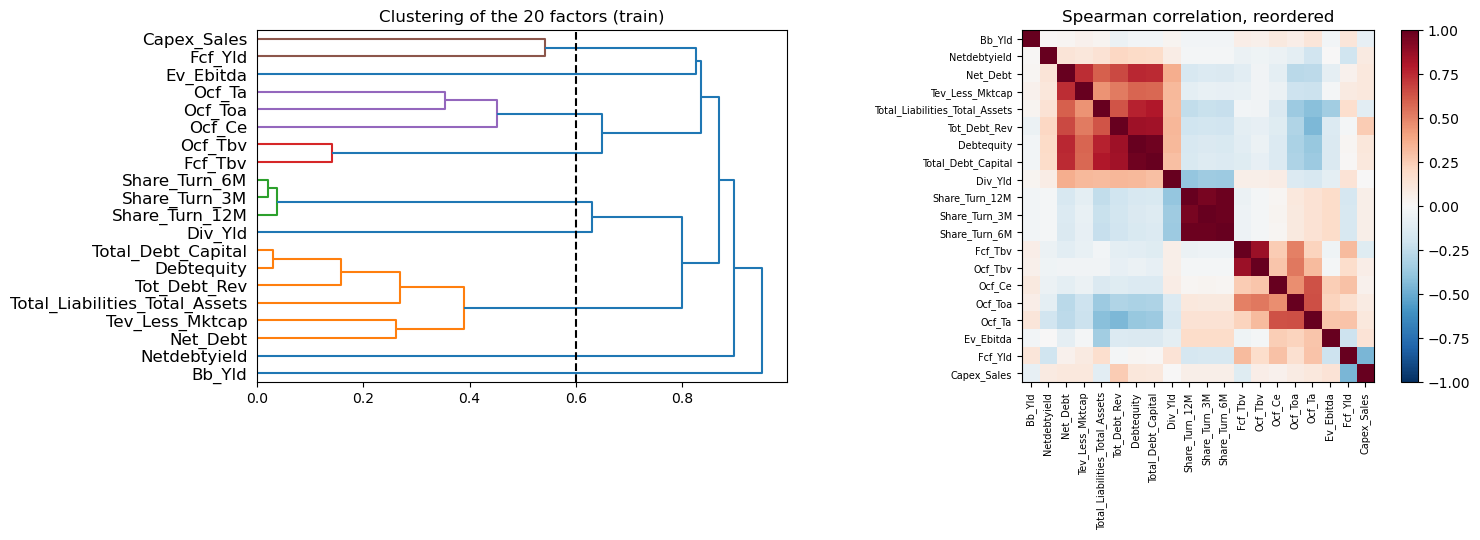

In [7]:
CLUSTER_DIST = 0.60            # 1-|rho| cut: factors with |rho| > 0.40 (average linkage) tend to merge

corr = train[FEATURES].corr(method="spearman")
dist = 1 - corr.abs()
Z = linkage(squareform(dist.values, checks=False), method="average")
labels = fcluster(Z, t=CLUSTER_DIST, criterion="distance")
groups = {}
for f, g in zip(FEATURES, labels):
    groups.setdefault(int(g), []).append(f)
for g, members in groups.items():
    print(f"group {g}: {members}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
dendrogram(Z, labels=FEATURES, orientation="right", ax=ax[0], color_threshold=CLUSTER_DIST)
ax[0].axvline(CLUSTER_DIST, ls="--", c="k"); ax[0].set_title("Clustering of the 20 factors (train)")
order = [FEATURES[i] for i in dendrogram(Z, no_plot=True)["leaves"]]
im = ax[1].imshow(corr.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(20)); ax[1].set_xticklabels(order, rotation=90, fontsize=7)
ax[1].set_yticks(range(20)); ax[1].set_yticklabels(order, fontsize=7)
ax[1].set_title("Spearman correlation, reordered"); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

## 4. Building the composites

All fitted objects (groups, signs, PCA loadings, IC weights) come from **train**. Each composite is re-ranked cross-sectionally per month so every new feature lives on the same 0-1 scale as the originals.

In [8]:
def xs_rank(df, series):
    """Cross-sectional percentile rank within each month."""
    return series.groupby(df["date"]).rank(pct=True)

# ---------- A. Cluster averages (unsupervised) ----------
# Within a group, flip any factor that is negatively correlated with the group anchor
# (anchor = member with highest average |corr| to the rest), then average.
fit = {"groups": groups, "signs": {}, "pca": {}, "ic_w": {}}
for g, members in groups.items():
    if len(members) == 1:
        fit["signs"][g] = {members[0]: 1}
        continue
    sub = corr.loc[members, members]
    anchor = sub.abs().mean().idxmax()
    fit["signs"][g] = {m: int(np.sign(sub.loc[anchor, m]) or 1) for m in members}

def cluster_avg(df):
    out = {}
    for g, members in groups.items():
        parts = [df[m] if fit["signs"][g][m] > 0 else 1 - df[m] for m in members]
        out[f"cl{g}_avg"] = xs_rank(df, sum(parts) / len(parts))
    return pd.DataFrame(out, index=df.index)

# ---------- B. PCA first component per multi-member group (unsupervised) ----------
scalers, pcas = {}, {}
for g, members in groups.items():
    if len(members) < 2: continue
    sc = StandardScaler().fit(train[members])
    p = PCA(n_components=1).fit(sc.transform(train[members]))
    # make the component point the same way as the group's sign-aligned average (arbitrary sign otherwise)
    avg = sum((train[m] if fit["signs"][g][m] > 0 else 1 - train[m]) for m in members)
    if np.corrcoef(p.transform(sc.transform(train[members]))[:, 0], avg)[0, 1] < 0:
        p.components_ *= -1
    scalers[g], pcas[g] = sc, p
    fit["pca"][g] = {"members": members, "explained_var": float(p.explained_variance_ratio_[0])}

def cluster_pca(df):
    out = {}
    for g in pcas:
        comp = pcas[g].transform(scalers[g].transform(df[groups[g]]))[:, 0]
        out[f"cl{g}_pc1"] = xs_rank(df, pd.Series(comp, index=df.index))
    return pd.DataFrame(out, index=df.index)

print({g: round(v["explained_var"], 2) for g, v in fit["pca"].items()}, "<- share of group variance kept by PC1")

{5: 0.72, 1: 0.75, 2: 0.98, 4: 0.93, 6: 0.73} <- share of group variance kept by PC1


In [9]:
# ---------- C. IC-weighted blend (supervised, train weights only) ----------
ic_train = monthly_ic(train, FEATURES)
w_all = ic_train.mean()                               # signed mean IC = weight; sign handles direction
fit["ic_w"]["all"] = w_all.round(5).to_dict()

def ic_blend(df, weights):
    z = sum(weights[f] * (df[f] - 0.5) for f in weights.index)   # centered ranks times IC weight
    return xs_rank(df, z)

# ---------- D. Greedy: best |ICIR| first, skip anything too correlated with an already chosen factor ----------
CORR_CAP, K_MAX = 0.60, 6
order = (ic_train.mean() / ic_train.std()).abs().sort_values(ascending=False).index
chosen = []
for f in order:
    if all(abs(corr.loc[f, c]) < CORR_CAP for c in chosen):
        chosen.append(f)
    if len(chosen) == K_MAX: break
w_pruned = w_all[chosen]
fit["ic_w"]["pruned_features"] = chosen
print("Greedy-chosen, decorrelated factors:", chosen)

# ---------- E. Hand-built economic composites (unsupervised, interpretable) ----------
def hand_built(df):
    leverage = df[["Debtequity","Total_Debt_Capital","Total_Liabilities_Total_Assets","Tot_Debt_Rev","Net_Debt"]].mean(axis=1)
    cashflow = df[["Ocf_Ta","Ocf_Toa","Ocf_Ce","Ocf_Tbv","Fcf_Tbv"]].mean(axis=1)
    payout   = df[["Div_Yld","Bb_Yld","Netdebtyield","Fcf_Yld"]].mean(axis=1)
    out = pd.DataFrame(index=df.index)
    out["hb_leverage"]       = xs_rank(df, leverage)
    out["hb_cashflow"]       = xs_rank(df, cashflow)
    out["hb_payout"]         = xs_rank(df, payout)
    out["hb_quality_minus_lev"] = xs_rank(df, cashflow - leverage)     # strong cash flow AND low leverage
    out["hb_turnover_trend"] = xs_rank(df, df["Share_Turn_3M"] - df["Share_Turn_12M"])  # liquidity rising or fading
    return out

def add_composites(df):
    parts = [df, cluster_avg(df), cluster_pca(df), hand_built(df)]
    parts.append(pd.DataFrame({"blend_ic_all": ic_blend(df, w_all),
                               "blend_ic_pruned": ic_blend(df, w_pruned)}, index=df.index))
    return pd.concat(parts, axis=1)

train_x, test_x = add_composites(train), add_composites(test)
NEW = [c for c in train_x.columns if c not in train.columns]
print("New composite columns:", NEW)

Greedy-chosen, decorrelated factors: ['Ocf_Ce', 'Ocf_Tbv', 'Fcf_Yld', 'Ocf_Toa', 'Netdebtyield', 'Capex_Sales']
New composite columns: ['cl5_avg', 'cl1_avg', 'cl2_avg', 'cl4_avg', 'cl6_avg', 'cl3_avg', 'cl8_avg', 'cl9_avg', 'cl7_avg', 'cl5_pc1', 'cl1_pc1', 'cl2_pc1', 'cl4_pc1', 'cl6_pc1', 'hb_leverage', 'hb_cashflow', 'hb_payout', 'hb_quality_minus_lev', 'hb_turnover_trend', 'blend_ic_all', 'blend_ic_pruned']


## 5. Do the composites help? (score vs the factors they replace)

Train is **in-sample for the supervised blends (C, D)**, so their train IC is optimistic by construction. Compare against test as a reality check (with the earlier caveat that test has been viewed).

In [10]:
tr = scorecard(train_x, NEW)
te = scorecard(test_x,  NEW)
res = pd.concat({"train": tr, "test": te}, axis=1)
res.sort_values(("train","mean_IC"), key=abs, ascending=False).round(4)

train                                test                            
                     mean_IC    ICIR pct_pos Q5_minus_Q1 mean_IC    ICIR pct_pos Q5_minus_Q1
blend_ic_all          0.0152  0.1424  0.5667      0.0101  0.0116  0.1220  0.5185      0.0043
blend_ic_pruned       0.0143  0.2398  0.5833      0.0048  0.0065  0.0959  0.5463      0.0006
cl5_avg               0.0103  0.1355  0.5750      0.0004  0.0038  0.0424  0.5370     -0.0007
cl5_pc1               0.0103  0.1337  0.5667      0.0002  0.0038  0.0421  0.5463     -0.0007
cl6_avg               0.0101  0.1155  0.5167      0.0056  0.0109  0.1229  0.5741      0.0040
cl6_pc1               0.0100  0.1150  0.5167      0.0058  0.0109  0.1227  0.5741      0.0040
hb_cashflow           0.0094  0.1478  0.5333      0.0009  0.0005  0.0073  0.5185     -0.0002
cl2_pc1              -0.0084 -0.0521  0.5000     -0.0122 -0.0139 -0.1048  0.4815     -0.0058
cl2_avg              -0.0084 -0.0519  0.5000     -0.0122 -0.0139 -0.1048  0.4815     -0.0058
hb_quality_minus_lev  0.0061  0.0649  0.5333     -0.0023 -0.0011 -0.0141  0.4722     -0.0018
cl8_avg              -0.0053 -0.1055  0.4917     -0.0030  0.0066  0.1137  0.5648      0.0009
cl4_pc1               0.0044  0.1005  0.5250      0.0014 -0.0030 -0.0673  0.4352     -0.0014
cl4_avg               0.0044  0.1002  0.5250      0.0015 -0.0030 -0.0663  0.4352     -0.0015
cl7_avg              -0.0036 -0.0418  0.4667     -0.0030  0.0060  0.0492  0.5463     -0.0018
hb_turnover_trend     0.0027  0.0414  0.5583     -0.0012  0.0035  0.0757  0.5093      0.0006
cl9_avg              -0.0027 -0.0492  0.5083      0.0011  0.0120  0.1670  0.5648      0.0015
hb_payout             0.0019  0.0168  0.5000      0.0036  0.0142  0.1581  0.5185      0.0038
hb_leverage          -0.0011 -0.0091  0.4750      0.0034  0.0016  0.0182  0.5185      0.0014
cl1_avg              -0.0003 -0.0025  0.4750      0.0037  0.0005  0.0058  0.4907      0.0012
cl1_pc1              -0.0003 -0.0022  0.4833      0.0038  0.0006  0.0068  0.5000      0.0012
cl3_avg              -0.0002 -0.0011  0.4750      0.0042  0.0010  0.0078  0.4722      0.0016

In [11]:
# How do composites compare with the single best original factors? (mean IC, test)
te_base = scorecard(test, FEATURES)
cmp = pd.DataFrame({
    "best single factor (test |IC|)": [te_base.mean_IC.abs().max()],
    "median single factor (test |IC|)": [te_base.mean_IC.abs().median()],
    "best composite (test |IC|)": [te.mean_IC.abs().max()],
    "median composite (test |IC|)": [te.mean_IC.abs().median()],
}).T
cmp.columns = ["value"]; print(cmp.round(4))

# Redundancy: average absolute pairwise correlation (train) before vs after
def mean_abs_corr(df, cols):
    c = df[cols].corr(method="spearman").abs().values
    return (c.sum() - len(cols)) / (len(cols) * (len(cols) - 1))
reduced = [f"cl{g}_avg" for g in groups]
print(f"\nmean |corr| among 20 raw factors : {mean_abs_corr(train_x, FEATURES):.3f}")
print(f"mean |corr| among {len(reduced)} cluster averages: {mean_abs_corr(train_x, reduced):.3f}")

                                   value
best single factor (test |IC|)    0.0143
median single factor (test |IC|)  0.0054
best composite (test |IC|)        0.0142
median composite (test |IC|)      0.0038

mean |corr| among 20 raw factors : 0.213
mean |corr| among 9 cluster averages: 0.129


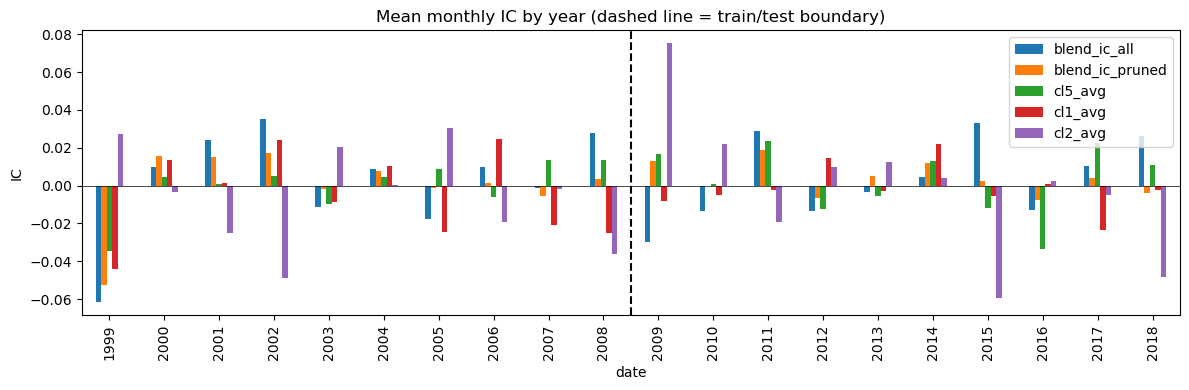

In [12]:
# Stability of the supervised blends: IC by calendar year, train then test.
ic_blend_all = monthly_ic(pd.concat([train_x, test_x]), ["blend_ic_all","blend_ic_pruned"] + [f"cl{g}_avg" for g in groups][:3])
yearly = ic_blend_all.groupby(ic_blend_all.index.year).mean()
ax = yearly.plot(kind="bar", figsize=(12, 4)); ax.axvline(9.5, c="k", ls="--"); ax.axhline(0, c="k", lw=.5)
ax.set_title("Mean monthly IC by year (dashed line = train/test boundary)"); ax.set_ylabel("IC"); plt.tight_layout(); plt.show()

## 6. Export the extended CSVs

Columns: original 23 + `fwd_log_ret` + raw technical (`ta_*`) + their ranks (`ta_*_rk`) + composites (`cl*_avg`, `cl*_pc1`, `hb_*`, `blend_ic_*`). The fitted objects are saved to `fit_params.json` so the recipe is reproducible. The source CSVs are not touched.

Rows in the first 12 train months have `NaN` in long-window technical features; drop or skip them when modeling (the models should see the same rows with and without technical features for a fair comparison).

In [13]:
keep = ["date","stock_id"] + FEATURES + [TARGET, "fwd_log_ret"] + TA_RAW + TA_RK + NEW
train_x[keep].to_csv(OUT / "mlfactor_fe_train.csv", index=False, float_format="%.6g")
test_x[keep].to_csv(OUT / "mlfactor_fe_test.csv", index=False, float_format="%.6g")
with open(OUT / "fit_params.json", "w") as fh:
    json.dump({**fit, "groups": {str(k): v for k, v in groups.items()},
               "signs": {str(k): v for k, v in fit["signs"].items()},
               "pca": {str(k): v for k, v in fit["pca"].items()},
               "cluster_dist": CLUSTER_DIST, "corr_cap": CORR_CAP}, fh, indent=2)
print("train", train_x[keep].shape, "| test", test_x[keep].shape)
print("test rows with any NaN in new columns:", int(test_x[NEW + TA_RK].isna().any(axis=1).sum()), "of", len(test_x))

train (140739, 67) | test (127740, 67)
test rows with any NaN in new columns: 120 of 127740


## 7. Takeaways / what to try next

- **Cluster average / PCA (A, B)** answer "which factors are saying the same thing" with no labels, so they cannot overfit returns. Use these as the default way to cut 20 inputs to ~6-8 for the 10-feature limit.
- **IC blends (C, D)** use labels; judge them on test/yearly stability, not on train IC.
- **Moving-average features** are the only inputs here that carry *new* information (price history) rather than recombining the same 20 factors.
- Next experiment: feed `cl*_avg` + a few `ta_*_rk` + `blend_ic_pruned` (<= 10 columns) into the existing four-model pipeline, tune with `GridSearchCV` on train only, and compare against the original 20 / ANOVA-10 / pruned-10 sets.